# IMDB Data Analysis with Logistic Regression with Stochastic Gradient Ascent

## Part A

## Importing Libraries

In [1]:
import numpy as np
import tensorflow as tf
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import precision_recall_fscore_support, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
from math import log

## Loading and Preprocessing IMDB Dataset

In [2]:
# Hyperparameters
m = 3000  # Vocabulary size
n = 50    # Skip top-N most frequent words
k = 20    # Skip bottom-K least frequent words

g = 800   # Number of most important features to keep (Information Gain)
infogain = True  # Enable Information Gain feature selection

# Load IMDB dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=m-k, skip_top=n)
word_index = tf.keras.datasets.imdb.get_word_index()

# Decode indices back to words
def decode_review(encoded_review, index2word):
    return ' '.join([index2word.get(idx, '?') for idx in encoded_review])

index2word = {i + 3: word for word, i in word_index.items()}
index2word.update({0: '[pad]', 1: '[bos]', 2: '[oov]'})

x_train = np.array([decode_review(review, index2word) for review in x_train])
x_test = np.array([decode_review(review, index2word) for review in x_test])

print("Training samples:", len(x_train))
print("Test samples:", len(x_test))

Training samples: 25000
Test samples: 25000


## Creating Binary Vectors

In [3]:
# Convert text to binary vectors
binary_vectorizer = CountVectorizer(binary=True)
x_train_binary = binary_vectorizer.fit_transform(x_train).toarray()
x_test_binary = binary_vectorizer.transform(x_test).toarray()

print("Vocabulary size:", len(binary_vectorizer.vocabulary_))

Vocabulary size: 2873


## Applying Information Gain for Feature Selection

In [4]:
if infogain:
    from math import log

    def IG(class_, feature):
        classes = set(class_)
        Hc = 0
        for c in classes:
            pc = list(class_).count(c) / len(class_)
            Hc += -pc * log(pc, 2)
        feature_values = set(feature)
        Hc_feature = 0
        for feat in feature_values:
            pf = list(feature).count(feat) / len(feature)
            indices = [i for i in range(len(feature)) if feature[i] == feat]
            clasess_of_feat = [class_[i] for i in indices]
            for c in classes:
                pcf = clasess_of_feat.count(c) / len(clasess_of_feat)
                if pcf != 0:
                    temp_H = -pf * pcf * log(pcf, 2)
                    Hc_feature += temp_H
        return Hc - Hc_feature

    ig = [(i, IG(y_train, x_train_binary[:, i])) for i in range(len(x_train_binary[0]))]
    ig.sort(key=lambda x: x[1], reverse=True)
    ig = ig[:g]
    x_train_binary = x_train_binary[:, [i[0] for i in ig]]
    x_test_binary = x_test_binary[:, [i[0] for i in ig]]

print("Reduced feature set size:", x_train_binary.shape[1])

Reduced feature set size: 800


## Implementing Logistic Regression Classifier

In [5]:
class LogisticRegressionSGd:
    def __init__(self, lamda_value=0.001, max_epochs=1000):
        self.weights = None
        self.eta = 0.01
        self.lamda = lamda_value
        self.max_epochs = max_epochs
        self.tolerance = 1e-3
        self.max_no_improvement = 5

    def predict(self, X):
        y_pred = list()
        X = np.insert(X, 0, 1, axis=1)  # Add bias term
        for x in X:
            y_pred.append(1 if np.dot(self.weights, x) > 0.0 else 0)
        return y_pred

    def prob_pos(self, x):
        return 1.0 / (1.0 + np.exp(-np.dot(x, self.weights)))

    def fit(self, X, y):
        X = np.insert(X, 0, 1, axis=1)  # Add bias term
        examples_num = X.shape[0]
        features_num = X.shape[1]
        self.weights = np.zeros(features_num)
        no_improvement = 0
        min_loss = 1

        for epoch in range(self.max_epochs):
            X, y = shuffle(X, y, random_state=0)
            loss = 0.0
            for i in range(examples_num):
                prob_pos = self.prob_pos(X[i])
                self.weights = (1 - 2 * self.lamda * self.eta) * self.weights + self.eta * (y[i] - prob_pos) * X[i]

                if prob_pos == 0.0:
                    prob_pos = 1e-300
                log_prob_pos = log(prob_pos)

                prob_neg = 1.0 - prob_pos
                if prob_neg == 0.0:
                    prob_neg = 1e-300
                log_prob_neg = log(prob_neg)

                loss -= y[i] * log_prob_pos + (1 - y[i]) * log_prob_neg

            loss /= examples_num

            if loss > min_loss + self.tolerance:
                no_improvement += 1

            if loss < min_loss:
                no_improvement = 0
                min_loss = loss

            if no_improvement == self.max_no_improvement:
                print("Number of training examples =", len(X), ":: Converged at epoch", epoch + 1, ":: Loss =", min_loss)
                break

## Finding the Best Regularization Parameter λ

In [6]:
# Define potential λ values
lambda_values = [0.01, 0.005, 0.001, 0.0005, 0.0001]

# Split data into training and validation sets
x_train_subset, x_dev, y_train_subset, y_dev = train_test_split(x_train_binary, y_train, test_size=0.2, random_state=42)

# Store results
best_lambda = None
best_accuracy = 0.0

for lamda in lambda_values:
    print(f"Evaluating for λ = {lamda}")
    model = LogisticRegressionSGd(lamda_value=lamda, max_epochs=1000)
    model.fit(x_train_subset, y_train_subset)
    y_pred_dev = model.predict(x_dev)
    accuracy = accuracy_score(y_dev, y_pred_dev)
    print(f"Validation Accuracy for λ = {lamda}: {accuracy}")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_lambda = lamda

print(f"Best λ: {best_lambda} with Validation Accuracy: {best_accuracy}")

Evaluating for λ = 0.01
Number of training examples = 20000 :: Converged at epoch 29 :: Loss = 0.4130942532285676
Validation Accuracy for λ = 0.01: 0.8396
Evaluating for λ = 0.005
Number of training examples = 20000 :: Converged at epoch 29 :: Loss = 0.3747876472405458
Validation Accuracy for λ = 0.005: 0.8496
Evaluating for λ = 0.001
Number of training examples = 20000 :: Converged at epoch 30 :: Loss = 0.3124107498409434
Validation Accuracy for λ = 0.001: 0.8638
Evaluating for λ = 0.0005
Number of training examples = 20000 :: Converged at epoch 53 :: Loss = 0.29600304644779435
Validation Accuracy for λ = 0.0005: 0.868
Evaluating for λ = 0.0001
Number of training examples = 20000 :: Converged at epoch 199 :: Loss = 0.2762718054933105
Validation Accuracy for λ = 0.0001: 0.8656
Best λ: 0.0005 with Validation Accuracy: 0.868


## Training and Evaluating the Model

In [7]:
# Train the model
# Train the model with the best λ
lr = LogisticRegressionSGd(lamda_value=best_lambda, max_epochs=1000)
lr.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test = lr.predict(x_test_binary)

# Display results
print("Test set evaluation:")
print(classification_report(y_test, y_pred_test))

# Compute metrics
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_test, average=None)
micro_avg = precision_recall_fscore_support(y_test, y_pred_test, average="micro")
macro_avg = precision_recall_fscore_support(y_test, y_pred_test, average="macro")

# Display metrics
print("Precision (class-wise):", precision)
print("Recall (class-wise):", recall)
print("F1-score (class-wise):", f1)
print("Micro-averaged metrics (Precision, Recall, F1):", micro_avg[:3])
print("Macro-averaged metrics (Precision, Recall, F1):", macro_avg[:3])

Number of training examples = 25000 :: Converged at epoch 52 :: Loss = 0.30001025183738245
Test set evaluation:
              precision    recall  f1-score   support

           0       0.86      0.88      0.87     12500
           1       0.88      0.86      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000

Precision (class-wise): [0.86307054 0.87928355]
Recall (class-wise): [0.88192 0.86008]
F1-score (class-wise): [0.87239346 0.86957577]
Micro-averaged metrics (Precision, Recall, F1): (0.871, 0.871, 0.871)
Macro-averaged metrics (Precision, Recall, F1): (0.8711770461060431, 0.871, 0.8709846153798395)


## Learning Curves: Precision, Recall, and F1

Number of training examples = 2000 :: Converged at epoch 295 :: Loss = 0.17755964067526306
Number of training examples = 4000 :: Converged at epoch 78 :: Loss = 0.23739363705176392
Number of training examples = 6000 :: Converged at epoch 148 :: Loss = 0.25628843927879286
Number of training examples = 8000 :: Converged at epoch 54 :: Loss = 0.2744607053874767
Number of training examples = 10000 :: Converged at epoch 76 :: Loss = 0.2845803350600409
Number of training examples = 12000 :: Converged at epoch 78 :: Loss = 0.28553140405642824
Number of training examples = 14000 :: Converged at epoch 48 :: Loss = 0.28995307387804803
Number of training examples = 16000 :: Converged at epoch 42 :: Loss = 0.29168381201840393
Number of training examples = 18000 :: Converged at epoch 34 :: Loss = 0.29359310903961733
Number of training examples = 20000 :: Converged at epoch 53 :: Loss = 0.29600304644779435


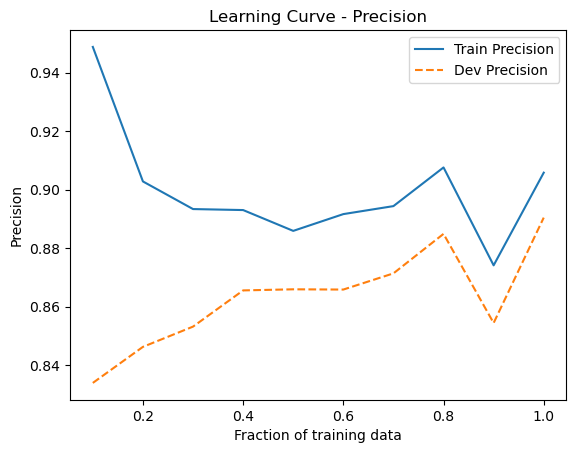

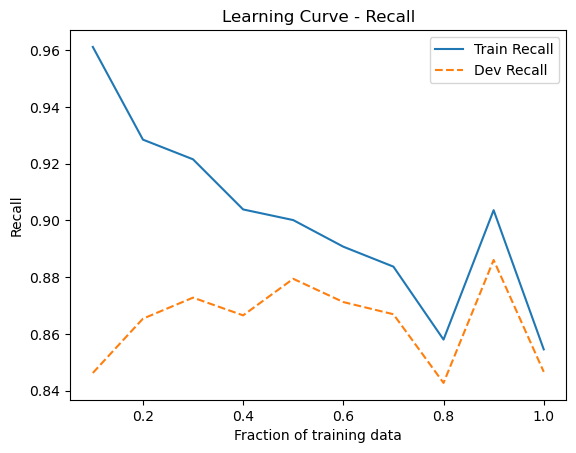

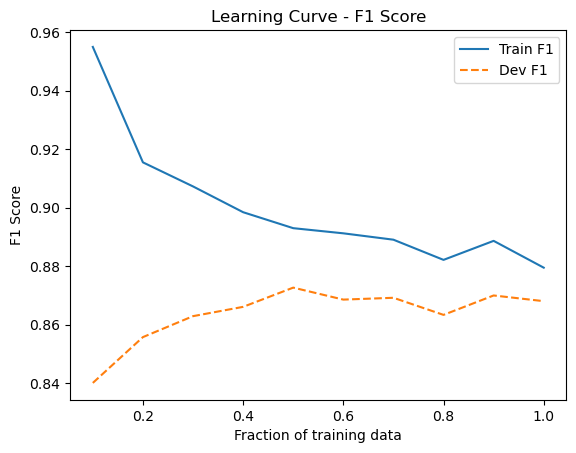

In [8]:
def plot_learning_curves(model, x_train, y_train, x_dev, y_dev, class_label):
    train_sizes = np.linspace(0.1, 1.0, 10)
    precision_vals, recall_vals, f1_vals = [], [], []
    dev_precision_vals, dev_recall_vals, dev_f1_vals = [], [], []

    for frac in train_sizes:
        subset_size = int(frac * len(y_train))
        x_subset, y_subset = x_train[:subset_size], y_train[:subset_size]

        model.fit(x_subset, y_subset)

        # Predictions on training subset
        y_pred_train = model.predict(x_subset)
        precision, recall, f1, _ = precision_recall_fscore_support(y_subset, y_pred_train, average=None)
        precision_vals.append(precision[class_label])
        recall_vals.append(recall[class_label])
        f1_vals.append(f1[class_label])

        # Predictions on development set
        y_pred_dev = model.predict(x_dev)
        dev_precision, dev_recall, dev_f1, _ = precision_recall_fscore_support(y_dev, y_pred_dev, average=None)
        dev_precision_vals.append(dev_precision[class_label])
        dev_recall_vals.append(dev_recall[class_label])
        dev_f1_vals.append(dev_f1[class_label])

    # Plotting Precision
    plt.figure()
    plt.plot(train_sizes, precision_vals, label="Train Precision")
    plt.plot(train_sizes, dev_precision_vals, label="Dev Precision", linestyle="--")
    plt.xlabel("Fraction of training data")
    plt.ylabel("Precision")
    plt.title("Learning Curve - Precision")
    plt.legend()
    plt.show()

    # Plotting Recall
    plt.figure()
    plt.plot(train_sizes, recall_vals, label="Train Recall")
    plt.plot(train_sizes, dev_recall_vals, label="Dev Recall", linestyle="--")
    plt.xlabel("Fraction of training data")
    plt.ylabel("Recall")
    plt.title("Learning Curve - Recall")
    plt.legend()
    plt.show()

    # Plotting F1 Score
    plt.figure()
    plt.plot(train_sizes, f1_vals, label="Train F1")
    plt.plot(train_sizes, dev_f1_vals, label="Dev F1", linestyle="--")
    plt.xlabel("Fraction of training data")
    plt.ylabel("F1 Score")
    plt.title("Learning Curve - F1 Score")
    plt.legend()
    plt.show()
    
# Split training data for learning curve evaluation
x_train_subset, x_dev, y_train_subset, y_dev = train_test_split(x_train_binary, y_train, test_size=0.2, random_state=42)

# Plot learning curves for class 1 (positive reviews)
plot_learning_curves(lr, x_train_subset, y_train_subset, x_dev, y_dev, class_label=1)

## Part B

## Comparing with Scikit-learn Implementations

In [9]:
# Importing Libraries
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

## Logistic Regression against Scikit-learn Bernoulli Naive Bayes

In [10]:
# Scikit-learn Bernoulli Naive Bayes
bnb_sklearn = BernoulliNB()
bnb_sklearn.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test_sklearn = bnb_sklearn.predict(x_test_binary)

# Display results
print("Scikit-learn Bernoulli Naive Bayes - Test set evaluation:")
print(classification_report(y_test, y_pred_test_sklearn))

Scikit-learn Bernoulli Naive Bayes - Test set evaluation:
              precision    recall  f1-score   support

           0       0.86      0.83      0.85     12500
           1       0.84      0.87      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



## Logistic Regression against Scikit-learn Random Forest Classifier

In [11]:
# Random Forest Classifier
#rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=5, random_state=42)

rf.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test_rf = rf.predict(x_test_binary)

# Display results
print("Random Forest Classifier - Test set evaluation:")
print(classification_report(y_test, y_pred_test_rf))

Random Forest Classifier - Test set evaluation:
              precision    recall  f1-score   support

           0       0.84      0.74      0.79     12500
           1       0.77      0.86      0.81     12500

    accuracy                           0.80     25000
   macro avg       0.81      0.80      0.80     25000
weighted avg       0.81      0.80      0.80     25000



## Logistic Regression against Scikit-learn Logistic Regression

In [12]:
# Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test_log_reg = log_reg.predict(x_test_binary)

# Display results
print("Logistic Regression - Test set evaluation:")
print(classification_report(y_test, y_pred_test_log_reg))

Logistic Regression - Test set evaluation:
              precision    recall  f1-score   support

           0       0.88      0.86      0.87     12500
           1       0.86      0.88      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



## Summary of Results

In [13]:
# Summary Table of Results
models = ["Logistic Regression", "Scikit-learn Bernoulli NB", "Scikit-learn Random Forest", "Scikit-learn Logistic Regression"]
results = [
    classification_report(y_test, y_pred_test, output_dict=True),
    classification_report(y_test, y_pred_test_sklearn, output_dict=True),
    classification_report(y_test, y_pred_test_rf, output_dict=True),
    classification_report(y_test, y_pred_test_log_reg, output_dict=True)
]

for model, result in zip(models, results):
    print("\nModel:", model)
    print("Accuracy:", result['accuracy'])
    print("Precision (weighted avg):", result['weighted avg']['precision'])
    print("Recall (weighted avg):", result['weighted avg']['recall'])
    print("F1-Score (weighted avg):", result['weighted avg']['f1-score'])


Model: Logistic Regression
Accuracy: 0.871
Precision (weighted avg): 0.8711770461060431
Recall (weighted avg): 0.871
F1-Score (weighted avg): 0.8709846153798395

Model: Scikit-learn Bernoulli NB
Accuracy: 0.84848
Precision (weighted avg): 0.8488967200094403
Recall (weighted avg): 0.84848
F1-Score (weighted avg): 0.8484347428567216

Model: Scikit-learn Random Forest
Accuracy: 0.80192
Precision (weighted avg): 0.8060265412683748
Recall (weighted avg): 0.80192
F1-Score (weighted avg): 0.8012532590612589

Model: Scikit-learn Logistic Regression
Accuracy: 0.87004
Precision (weighted avg): 0.8701210713194619
Recall (weighted avg): 0.87004
F1-Score (weighted avg): 0.870032883000673


## Learning Curves: Precision, Recall, and F1

Scikit-learn Bernoulli Naive Bayes

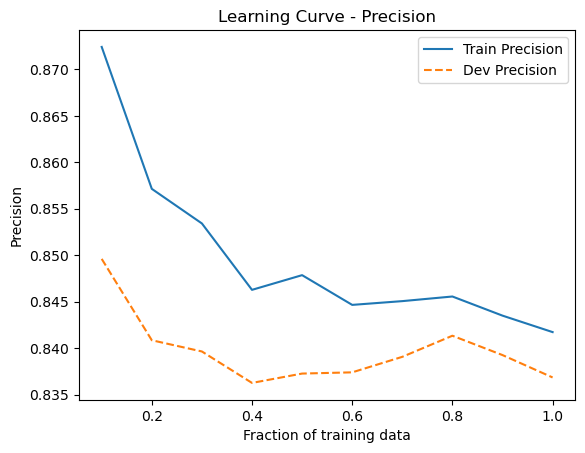

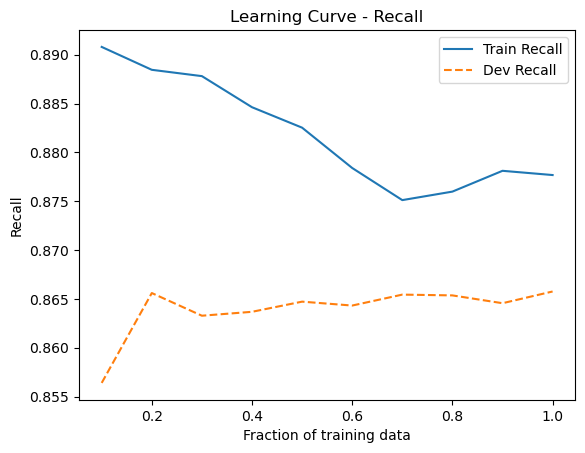

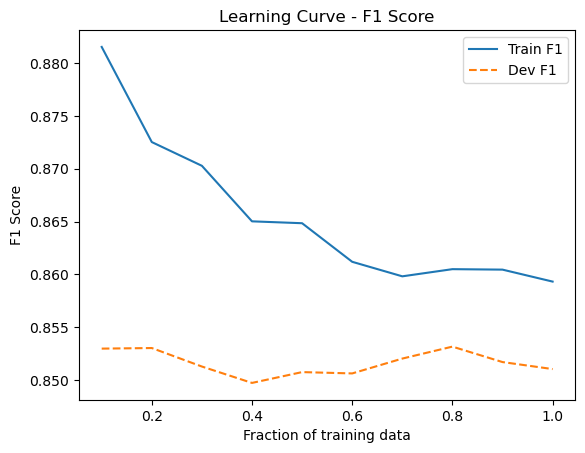

In [14]:
plot_learning_curves(bnb_sklearn, x_train_binary, y_train, x_test_binary, y_test, class_label=1)

Scikit-learn Random Forest

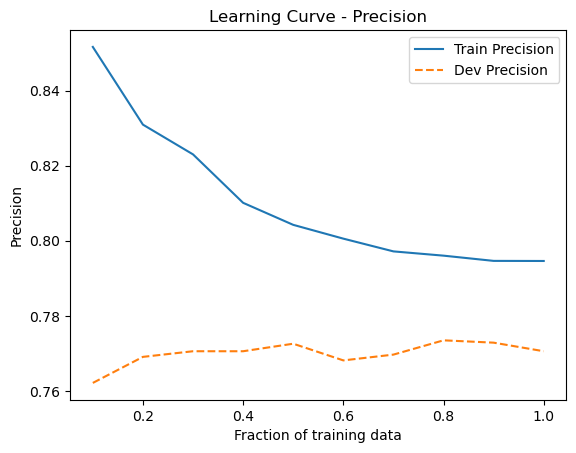

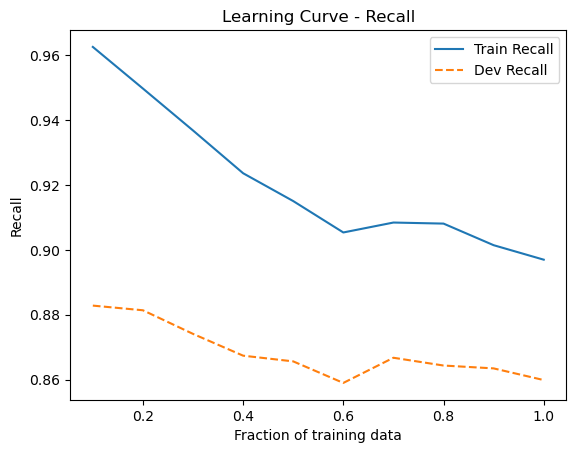

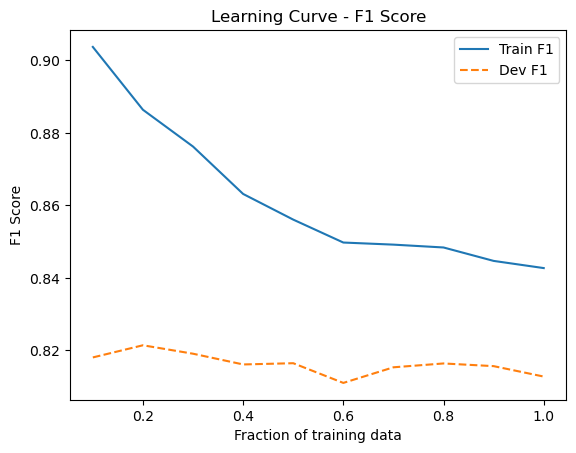

In [15]:
plot_learning_curves(rf, x_train_binary, y_train, x_test_binary, y_test, class_label=1)

Scikit-learn Logistic Regression

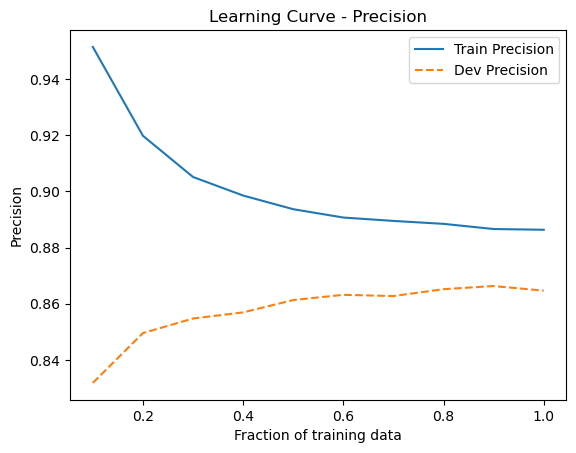

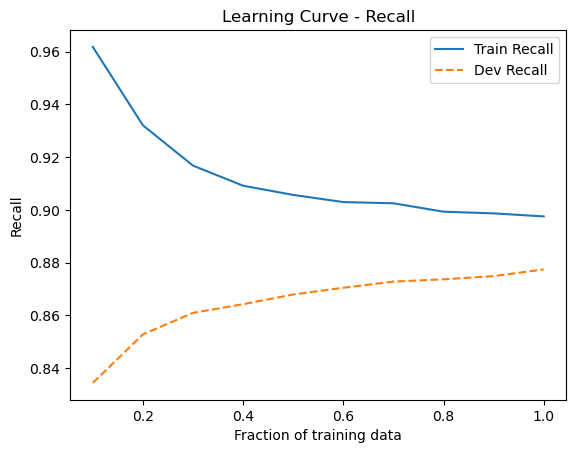

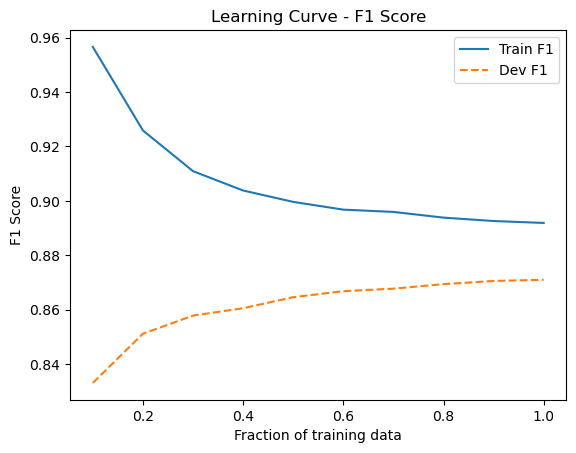

In [16]:
plot_learning_curves(log_reg, x_train_binary, y_train, x_test_binary, y_test, class_label=1)